<a href="https://colab.research.google.com/github/Charmmaine/Zara-Revenue-Analysis/blob/main/Zara_profit_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
#Importing Libraries#
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [7]:
# loading the data
URL = "https://raw.githubusercontent.com/Charmmaine/Zara-Revenue-Analysis/refs/heads/main/zara.csv"

df = pd.read_csv(URL,sep=";")

In [8]:
df.shape

(252, 16)

In [9]:
df.head()

,Product ID,Product Position,Promotion,Product Category,Seasonal,Sales Volume,brand,url,sku,name,description,price,currency,scraped_at,terms,section
0,185102,Aisle,No,Clothing,No,2823,Zara,https://www.zara.com/us/en/basic-puffer-jacket...,272145190-250-2,BASIC PUFFER JACKET,Puffer jacket made of tear-resistant ripstop f...,19.99,USD,2024-02-19T08:50:05.654618,jackets,MAN
1,188771,Aisle,No,Clothing,No,654,Zara,https://www.zara.com/us/en/tuxedo-jacket-p0889...,324052738-800-46,TUXEDO JACKET,Straight fit blazer. Pointed lapel collar and ...,169.00,USD,2024-02-19T08:50:06.590930,jackets,MAN
2,180176,End-cap,Yes,Clothing,Yes,2220,Zara,https://www.zara.com/us/en/slim-fit-suit-jacke...,335342680-800-44,SLIM FIT SUIT JACKET,Slim fit jacket. Notched lapel collar. Long sl...,129.00,USD,2024-02-19T08:50:07.301419,jackets,MAN
3,112917,Aisle,Yes,Clothing,Yes,1568,Zara,https://www.zara.com/us/en/stretch-suit-jacket...,328303236-420-44,STRETCH SUIT JACKET,Slim fit jacket made of viscose blend fabric. ...,129.00,USD,2024-02-19T08:50:07.882922,jackets,MAN
4,192936,End-cap,No,Clothing,Yes,2942,Zara,https://www.zara.com/us/en/double-faced-jacket...,312368260-800-2,DOUBLE FACED JACKET,Jacket made of faux leather faux shearling wit...,139.00,USD,2024-02-19T08:50:08.453847,jackets,MAN


In [10]:
df.tail()

,Product ID,Product Position,Promotion,Product Category,Seasonal,Sales Volume,brand,url,sku,name,description,price,currency,scraped_at,terms,section
247,159182,Front of Store,Yes,Clothing,No,1014,Zara,https://www.zara.com/us/en/basic-100-wool-swea...,321993245-500-2,FAUX LEATHER OVERSIZED JACKET LIMITED EDITION,Jacket made of technical fabric with padded in...,169.00,USD,2024-02-19T09:10:43.883037,jackets,MAN
248,199233,Aisle,Yes,Clothing,No,2222,Zara,https://www.zara.com/us/en/colorblock-knit-cro...,330590505-500-2,CONTRASTING PATCHES BOMBER JACKET,Oversized jacket. Notched lapel collar and lon...,159.00,USD,2024-02-19T09:10:44.463883,jackets,MAN
249,137044,Aisle,No,Clothing,Yes,2534,Zara,https://www.zara.com/us/en/hooded-technical-ja...,320680326-107-39,PATCH BOMBER JACKET,Varsity jacket with elastic collar and long sl...,12.99,USD,2024-02-19T09:10:45.009106,jackets,MAN
250,154736,Front of Store,Yes,Clothing,Yes,1466,Zara,https://www.zara.com/us/en/houndstooth-suit-ja...,311292244-800-39,CROPPED BOMBER JACKET LIMITED EDITION,Varsity jacket with padded interior. Rib elast...,19.90,USD,2024-02-19T09:10:45.631804,jackets,MAN
251,141434,Front of Store,No,Clothing,Yes,2870,Zara,https://www.zara.com/us/en/bomber-jacket-p0534...,311307610-400-39,FAUX LEATHER PUFFER JACKET,Jacket with lightly padded interior. Rib colla...,39.90,USD,2024-02-19T09:10:31.877972,jackets,MAN


In [11]:
df.dtypes

,0
Product ID,int64
Product Position,object
Promotion,object
Product Category,object
Seasonal,object
Sales Volume,int64
brand,object
url,object
sku,object
name,object


In [12]:
# Summary statistics

df.describe()

,Product ID,Sales Volume,price
count,252.000000,252.000000,252.000000
mean,153370.503968,1823.702381,86.252540
std,26160.444549,697.703748,52.083205
min,110075.000000,529.000000,7.990000
25%,131053.750000,1243.000000,49.900000
50%,151681.500000,1839.500000,79.900000
75%,175669.750000,2398.750000,109.000000
max,199631.000000,2989.000000,439.000000


In [13]:
#Checking missing values
df.isnull().sum()

,0
Product ID,0
Product Position,0
Promotion,0
Product Category,0
Seasonal,0
Sales Volume,0
brand,0
url,0
sku,0
name,1


In [14]:
#Filling the missing values with a place holder
df['name']= df['name'].fillna('Unkown Product')
df['description'] =df['description'].fillna("No description provided")
print(df.isnull().sum())

Product ID          0
Product Position    0
Promotion           0
Product Category    0
Seasonal            0
Sales Volume        0
brand               0
url                 0
sku                 0
name                0
description         0
price               0
currency            0
scraped_at          0
terms               0
section             0
dtype: int64


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
# item category names and their counts
print(df["terms"].value_counts())

terms
jackets     140
sweaters     41
t-shirts     32
shoes        31
jeans         8
Name: count, dtype: int64


In [17]:
# Calculating the revenue and adding it as a column in the data frame
df["revenue"] = df["price"] * df["Sales Volume"]
print(df.columns)

Index(['Product ID', 'Product Position', 'Promotion', 'Product Category',
       'Seasonal', 'Sales Volume', 'brand', 'url', 'sku', 'name',
       'description', 'price', 'currency', 'scraped_at', 'terms', 'section',
       'revenue'],
      dtype='object')


In [18]:
# Revenue from each category
print(df.groupby("terms")["revenue"].sum().round(-3))

terms
jackets     26582000.0
jeans         864000.0
shoes        3755000.0
sweaters     4091000.0
t-shirts     3697000.0
Name: revenue, dtype: float64


/tmp/ipykernel_4132/3292104622.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_rev, x='terms', y='revenue', palette='Blues_r')


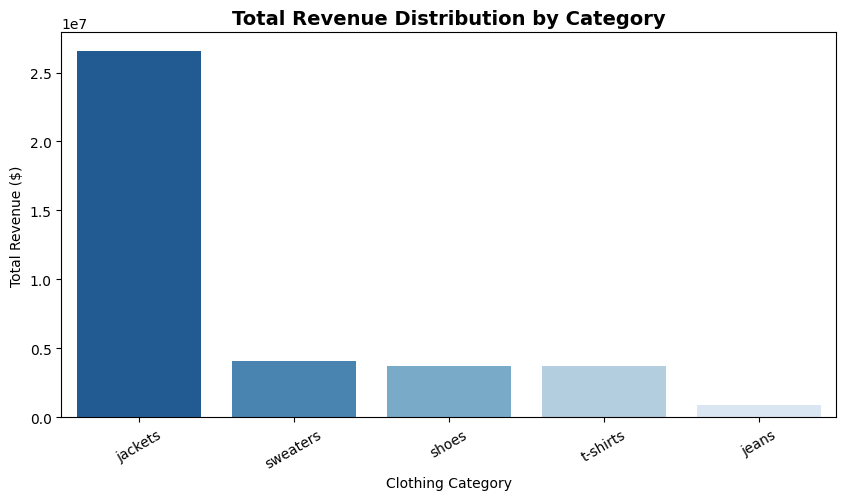

In [19]:
# 1. Calculate total revenue for each unique clothing type
cat_rev = df.groupby('terms')['revenue'].sum().sort_values(ascending=False).reset_index()

# 2. Set the window size and draw the standalone bar graph
plt.figure(figsize=(10, 5))
sns.barplot(data=cat_rev, x='terms', y='revenue', palette='Blues_r')

# 3. Add labels and display the graph
plt.title('Total Revenue Distribution by Category', fontsize=14, fontweight='bold')
plt.xlabel('Clothing Category')
plt.ylabel('Total Revenue ($)')
plt.xticks(rotation=30)
plt.show()

Text(0, 0.5, 'Average Units Sold (Sales Volume)')

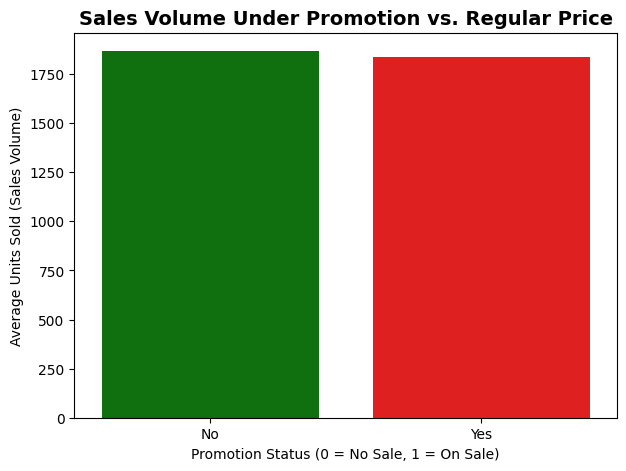

In [20]:
# 1. Filter the entire dataset to pull out ONLY rows where the category is 'jackets'
jacket_data = df[df['terms'].str.lower() == 'jackets']

# 2. Set the frame size for your second standalone graph
plt.figure(figsize=(7, 5))

# 3. Draw a bar chart comparing average sales volume when promotion is 0 (No) vs 1 (Yes)
sns.barplot(
    data=jacket_data,
    x='Promotion',
    y='Sales Volume',
    hue='Promotion',
    errorbar=None,
    palette={"No": 'green', "Yes": 'red'},
    legend=False
)
# 4. Add deep-dive specific labels
plt.title('Sales Volume Under Promotion vs. Regular Price', fontsize=14, fontweight='bold')
plt.xlabel('Promotion Status (0 = No Sale, 1 = On Sale)')
plt.ylabel('Average Units Sold (Sales Volume)')

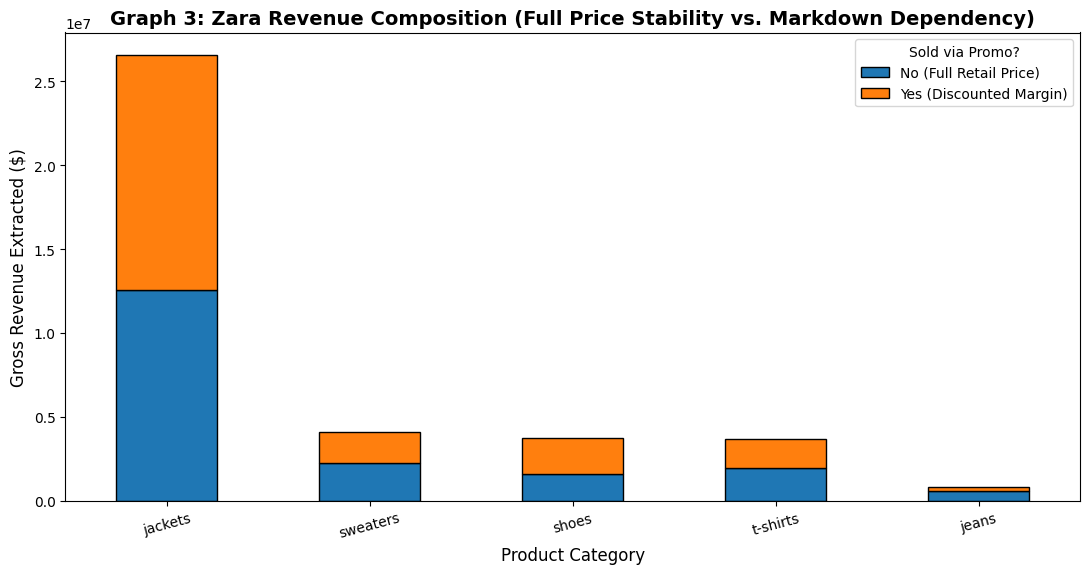

In [21]:
# 1. Create a summary table splitting revenue by category and promotion
revenue_split = df.pivot_table(values='revenue', index='terms', columns='Promotion', aggfunc='sum')

# 2. Arrange categories in the exact same order as your first graph (highest revenue to lowest)
# Note: If your column name is slightly different, adjust 'Jackets' or other names to match your dataset
category_order = df.groupby('terms')['revenue'].sum().sort_values(ascending=False).index
revenue_split = revenue_split.reindex(category_order)

# 3. Set up the plotting window
plt.figure(figsize=(11, 6))

# 4. Plot a stacked bar chart (Blue = Healthy Full Price, Orange = Discounted Risk)
revenue_split.plot(kind='bar', stacked=True, color={'No': '#1f77b4', 'Yes': '#ff7f0e'}, edgecolor='black', ax=plt.gca())

# 5. Add business-focused labels and titles
plt.title('Graph 3: Zara Revenue Composition (Full Price Stability vs. Markdown Dependency)', fontsize=14, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Gross Revenue Extracted ($)', fontsize=12)
plt.legend(title='Sold via Promo?', labels=['No (Full Retail Price)', 'Yes (Discounted Margin)'])
plt.xticks(rotation=15)

# 6. Save the image to your Colab workspace
plt.tight_layout()
plt.savefig('zara_3_profit_bleed.png', dpi=300)
plt.show()


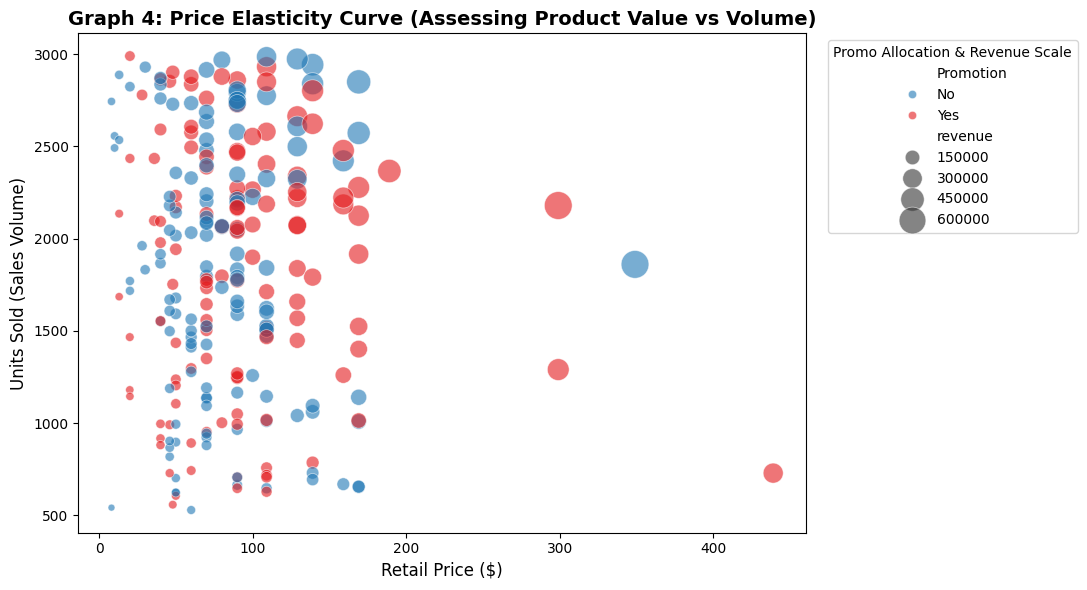

In [22]:
# 1. Set up the plotting window
plt.figure(figsize=(11, 6))

# 2. Build the Scatter Plot using your lowercase 'revenue' column
sns.scatterplot(
    data=df,
    x='price',
    y='Sales Volume',
    hue='Promotion',
    size='revenue',          # Updated to your lowercase column name
    sizes=(25, 400),
    palette={'No': '#1f77b4', 'Yes': '#e31a1c'},
    alpha=0.6
)

# 3. Add clean business-focused labels and titles
plt.title('Graph 4: Price Elasticity Curve (Assessing Product Value vs Volume)', fontsize=14, fontweight='bold')
plt.xlabel('Retail Price ($)', fontsize=12)
plt.ylabel('Units Sold (Sales Volume)', fontsize=12)

# 4. Push the legend to the side so it doesn't block the data points
plt.legend(title='Promo Allocation & Revenue Scale', bbox_to_anchor=(1.02, 1), loc='upper left')

# 5. Save the image to your Colab workspace
plt.tight_layout()
plt.savefig('zara_4_price_elasticity.png', dpi=300)
plt.show()


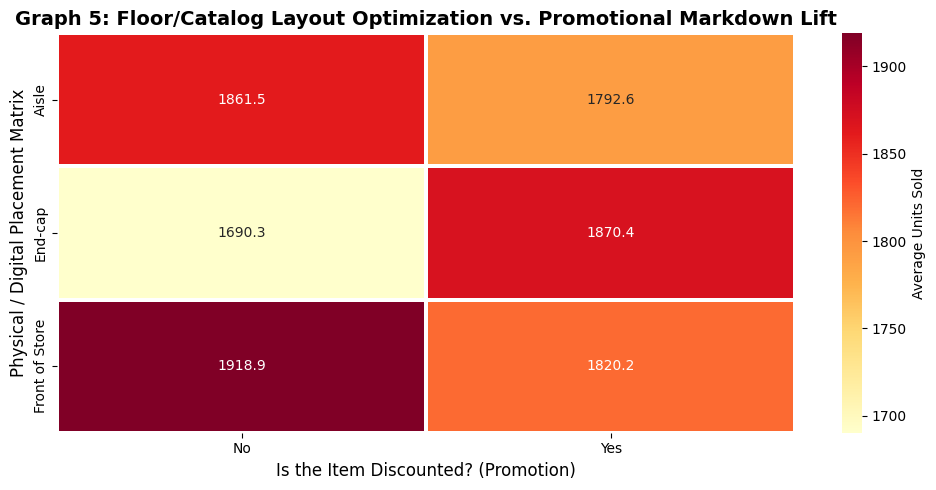

In [23]:
# 1. Create a pivot matrix calculating average sales volume by floor position and promotion status
heatmap_data = df.pivot_table(
    values='Sales Volume',
    index='Product Position',
    columns='Promotion',
    aggfunc='mean'
)

# 2. Set up the plotting window
plt.figure(figsize=(10, 5))

# 3. Build a clean, annotated heatmap matrix using an orange/red color gradient
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap='YlOrRd',
    linewidths=1.5,
    cbar_kws={'label': 'Average Units Sold'}
)

# 4. Add business-focused labels and title
plt.title('Graph 5: Floor/Catalog Layout Optimization vs. Promotional Markdown Lift', fontsize=14, fontweight='bold')
plt.xlabel('Is the Item Discounted? (Promotion)', fontsize=12)
plt.ylabel('Physical / Digital Placement Matrix', fontsize=12)

# 5. Save the graphic to your Colab directory
plt.tight_layout()
plt.savefig('zara_5_layout_heatmap.png', dpi=300)
plt.show()

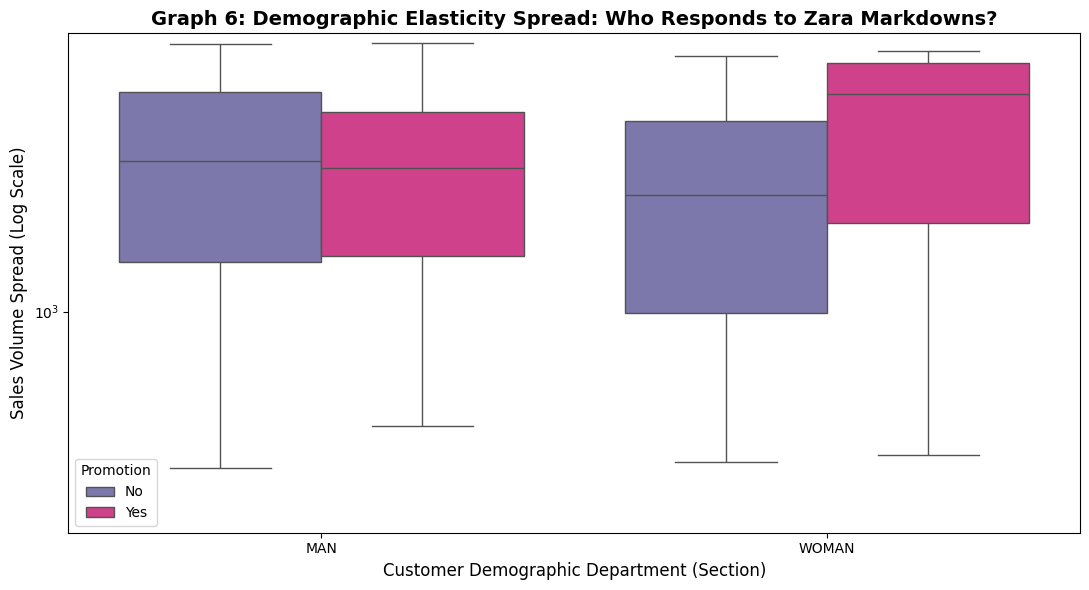

In [24]:
# 1. Set up the plotting window
plt.figure(figsize=(11, 6))

# 2. Build the demographic boxplot
sns.boxplot(
    data=df,
    x='section',
    y='Sales Volume',
    hue='Promotion',
    palette={'No': '#7570b3', 'Yes': '#e7298a'},
    fliersize=3
)

# 3. Apply a symmetric log scale to handle extreme sales surges smoothly without crushing the boxes
plt.yscale('symlog')

# 4. Add clear labels and title
plt.title('Graph 6: Demographic Elasticity Spread: Who Responds to Zara Markdowns?', fontsize=14, fontweight='bold')
plt.xlabel('Customer Demographic Department (Section)', fontsize=12)
plt.ylabel('Sales Volume Spread (Log Scale)', fontsize=12)

# 5. Clean up spacing and save the image to your Colab panel
plt.tight_layout()
plt.savefig('zara_6_demographic_boxplot.png', dpi=300)
plt.show()
